# AI651 – Deep Learning for Space, Time and Graphs — Assignment 3 Report
**Roll number:** 24030023

**GitHub repository:** https://github.com/TahaRazzaq/DL4STG 

All experiments are in `24030023_PA3.ipynb`. Saved figures, results and model weights are in `outputs/`.

## Question 1 – What does a sum remember?

### (a) Affine message
$$\sum_{u\in N(v)}(w x_u + c) = w\,S_v + c\,n_v .$$
The aggregate depends on the neighbourhood only through $(n_v, S_v)$. If two neighbourhoods have equal $n_v$ and $S_v$, $\rho$ receives the same number for every $w, c$, so $h_v$ is identical for every $\rho$.

**Example:** $N_1=\{-1,+1\}$ (0 steady) and $N_2=\{0,0\}$ (2 steady) both have $n_v=2,\ S_v=0$.

### (b) Injective scalar message
Let $B=K+1$ and set $\phi(-1)=1,\ \phi(0)=B,\ \phi(+1)=B^2$. Then
$$s=\sum_u \phi(x_u)=n_- + n_0 B + n_+ B^2 .$$
Each count is at most $K<B$, so the three counts are the base-$B$ digits of $s$ with no carries, and $s$ is unique.

**Decoding:** $n_- = s \bmod B,\quad n_0=\lfloor s/B\rfloor \bmod B,\quad n_+=\lfloor s/B^2\rfloor$.

For $K=8$: $\phi=(1,\,9,\,81)$. NumPy check: all **164** count triples with $1\le n_v\le 8$ give **164 distinct sums**, and every triple is decoded correctly.

**Counting non-steady neighbours:** $\phi(x)=x^2$ gives $\sum_u \phi(x_u)=n_-+n_+$ for any neighbourhood size.

### (c) Sum vs Mean vs Max (one-hot messages)
The aggregate is $(a_-, a_0, a_+)$. Every neighbourhood of size 1–8 was checked exhaustively in the notebook.

| Task | Method | Possible? | Reason |
|---|---|---|---|
| (i) Count steady | Sum | Yes | $\rho$ returns $a_0$ |
| | Mean | No | $\{0\}$ and $\{0,0\}$ both give $(0,1,0)$; answers 1 vs 2 |
| | Max | No | $\{0\}$ and $\{0,0\}$ both give $(0,1,0)$; answers 1 vs 2 |
| (ii) More than half slowing | Sum | Yes | $a_- > a_0 + a_+$ |
| | Mean | Yes | $a_- > 1/2$ |
| | Max | No | $\{-1,0\}$ and $\{-1,-1,0\}$ both give $(1,1,0)$; answers No vs Yes |
| (iii) Any slowing | Sum | Yes | $a_- > 0$ |
| | Mean | Yes | $a_- > 0$ |
| | Max | Yes | $a_- = 1$ |

## Question 2 – Which way is the slowdown moving?

### (a)(i) Symmetric layer fitted to one impulse
Input: $x_{20}=1$, all other sensors 0. Target: $x_{19}=1$, all others 0.

| Sensor | 19 | 20 | 21 |
|---|---|---|---|
| Prediction | $b$ | $a$ | $b$ |
| Target | 1 | 0 | 0 |

All other predictions are 0. The loss is
$$L=(b-1)^2+a^2+b^2,\qquad \partial_a L=2a=0,\quad \partial_b L=2(b-1)+2b=0 .$$
Solving gives $a=0,\ b=\tfrac12$, with minimum SSE $=\tfrac12$.

### (a)(ii) Rollout on the smooth bump

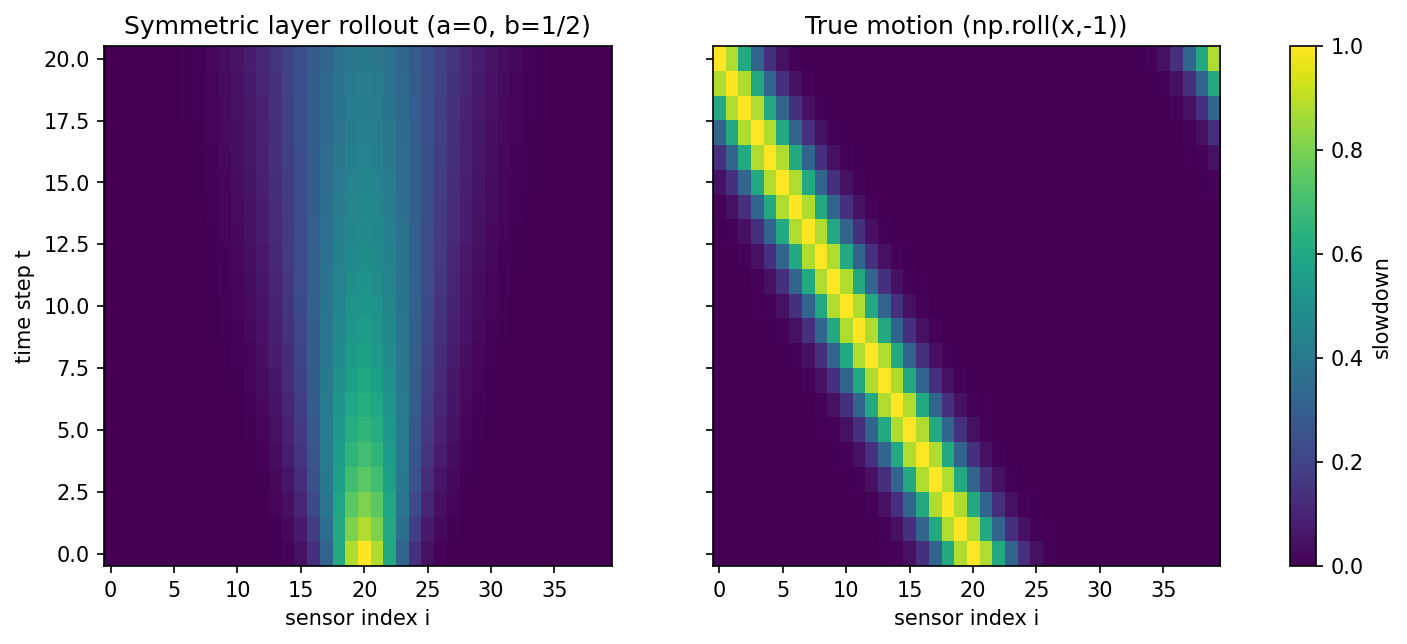

The symmetric layer pushes half of each value to both neighbours. The bump stays centred at sensor 20 and spreads out and flattens: its peak falls from 1 to 0.41 after 20 steps. The true bump moves 20 sensors against traffic, to sensor 0, without changing shape.

### (b) Direction-aware weights
Use $a=0,\ w_-=0,\ w_+=1$. Then $\hat x_i(t+1)=x_{i+1}(t)$, which is exactly the motion rule, for every input.

In (a) both neighbours share the weight $b$, so the layer cannot tell the downstream neighbour from the upstream one and has to split the value between them. Separate weights tell the layer which neighbour is ahead, so it can copy only $x_{i+1}$.

**As a 1D convolution:** the kernel applied to $[x_{i-1}, x_i, x_{i+1}]$ is $[0,\,0,\,1]$, with **circular padding** of 1 so that sensor 39 sees sensor 0. This was verified with `nn.Conv1d(padding_mode='circular')`.

### (c) Adding history with equal neighbour weights
**(i) Backward motion.** $x_i(t)=x_{i+1}(t-1)$, so $x_i(t-1)=x_{i-1}(t)$. With $a=0,\ b=1,\ c=-1$:
$$\hat x_i(t+1)=x_{i-1}(t)+x_{i+1}(t)-x_{i-1}(t)=x_{i+1}(t)=x_i(t+1)\ \checkmark$$

**(ii) Forward motion.** $x_i(t)=x_{i-1}(t-1)$, so $x_i(t-1)=x_{i+1}(t)$. With the same coefficients:
$$\hat x_i(t+1)=x_{i-1}(t)+x_{i+1}(t)-x_{i+1}(t)=x_{i-1}(t)=x_i(t+1)\ \checkmark$$
The same coefficients are exact in both directions. This was verified on 100 random patterns for each direction.

**(iii)** The previous reading at sensor $i$ now sits at the neighbour the pattern came from. Subtracting it cancels that neighbour's contribution and leaves the neighbour the pattern is moving toward. The direction is read from the history, not from different spatial weights.

## Question 3 – Dataset preparation and graph construction

### (a) Extraction and resampling
- **Files:** `ca_his_raw_2020.h5`, `ca_his_raw_2021.h5`, `ca_meta.csv` and `ca_rn_adj.npy` from Kaggle `liuxu77/largest`.
- **San Diego subset:** Caltrans District 11 in `ca_meta.csv`, which gives **716 sensors**. Only these columns are read.
- **Period:** 2020–2021. That is 210,528 five-minute steps, or **70,176 fifteen-minute steps**.
- **Aggregation:** LargeST flow is the vehicle count in each 5-min interval, so 15-min values are the **sum** of the three counts (units: vehicles / 15 min). If only some of the three are present, the sum is estimated as $3\times$ their mean.

**Missing values**

| | Value |
|---|---|
| Missing 5-min values | 5.07% |
| Missing 15-min values | 5.06% |
| Partially observed 15-min intervals | 0.02% |
| Sensors with no data at all | 19 |
| Sensors more than 50% missing | 43 |

**Handling:**
- A mask of observed values is kept. The loss and all metrics use **only observed targets**.
- Model inputs are forward-filled; leading gaps at the start of 2020 are back-filled.
- The 19 sensors with no data are filled with the training mean (607.39).

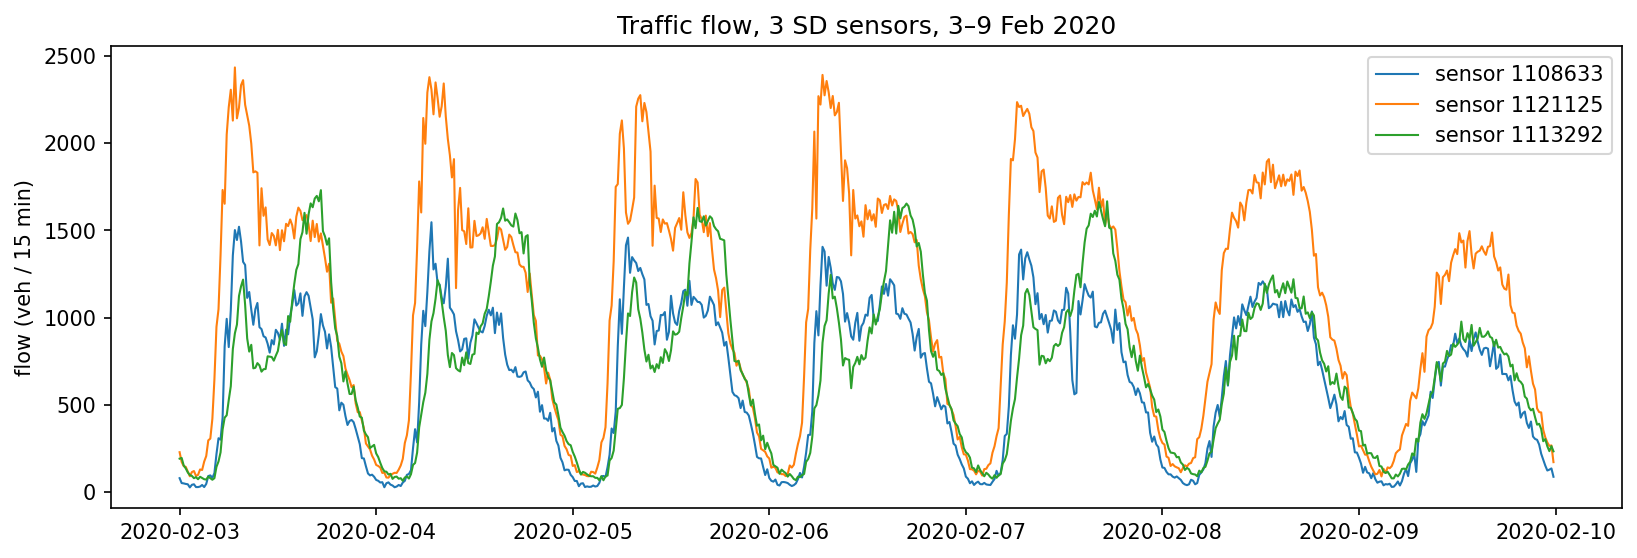

### (b) Traffic graph
The adjacency is $A_{SD} =$ `ca_rn_adj[idx][:, idx]`, where `idx` are the row positions of the SD sensors in `ca_meta.csv`. The same positions select the traffic columns, so the sensor ordering matches.

| Property | Value |
|---|---|
| Nodes | 716 |
| Nonzero edges (off-diagonal) | 17,319 (plus 716 self-loops) |
| Symmetric | **No** (directed) |
| Edge weights | 0.01 – 1.0 |
| Neighbours per sensor | mean 24.2, median 20, max 70; 8 sensors have none |

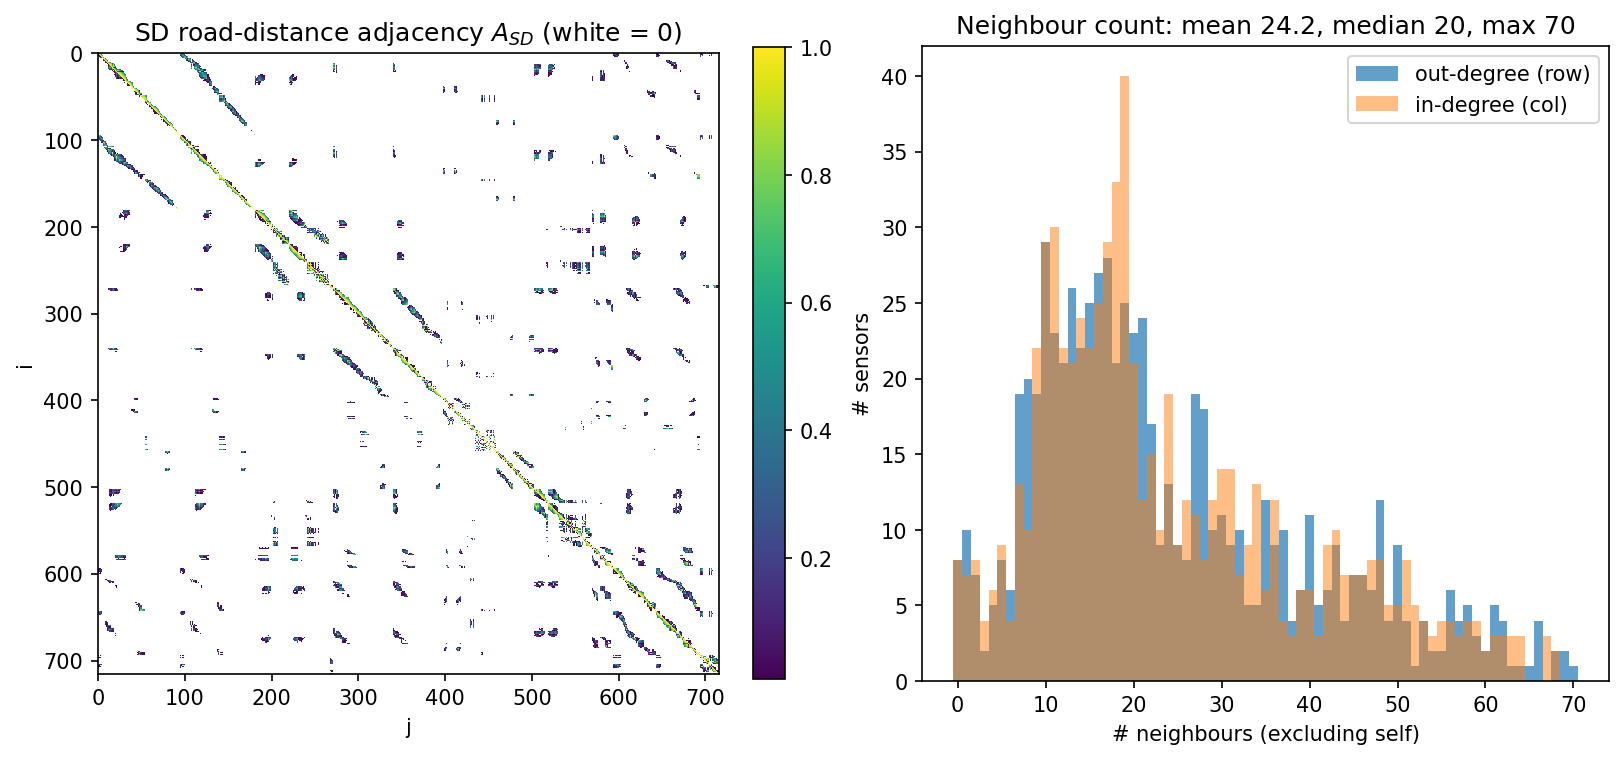

**Meaning of $A_{ij}\neq 0$:** sensor $j$ is connected to sensor $i$ in the road network. The value is a connection strength that falls with the road distance between them (a thresholded Gaussian kernel of road distance; weak links are removed). Because road distance depends on direction, $A_{ij}\neq A_{ji}$ in general.

### (c) Neighbourhoods
For sensor **1126411** (index 33), which has a median-sized neighbourhood:
- **1-hop:** 20 sensors.
- **Within 2 hops:** 73 sensors, of which 53 are new at the second hop.

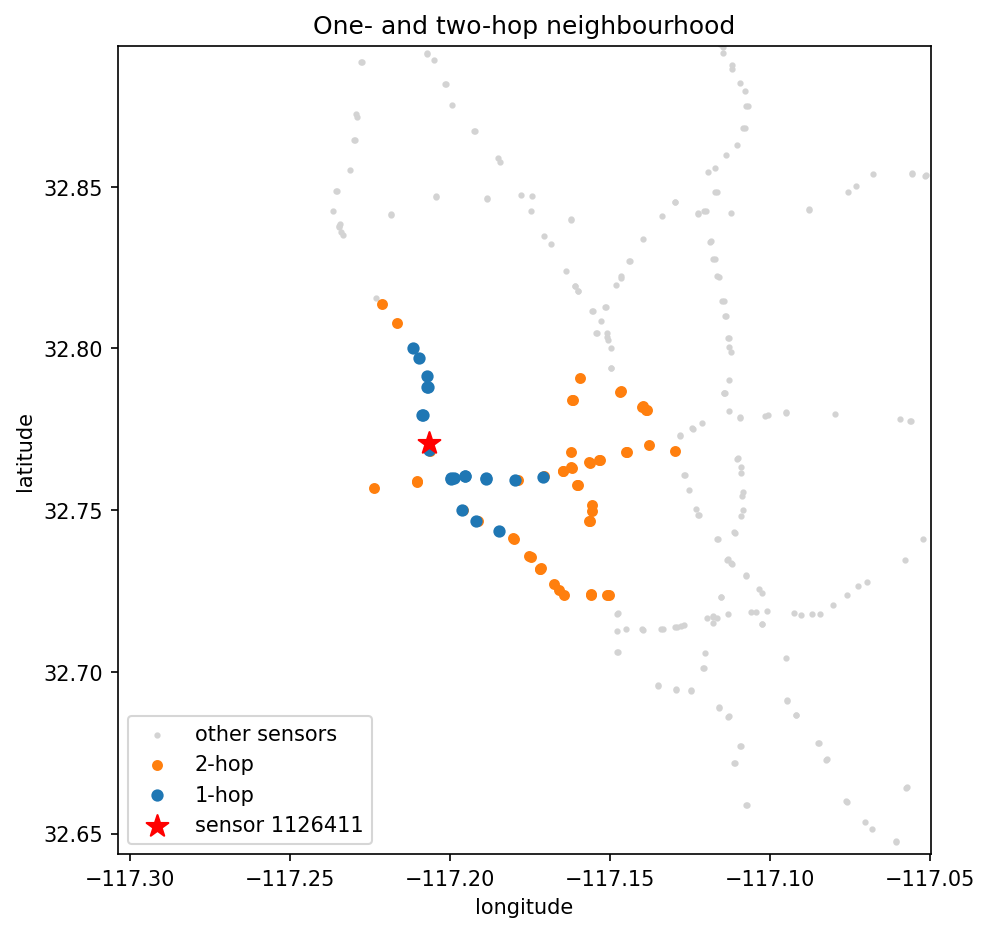

- **Why neighbours help:** traffic moves along the road, so congestion upstream reaches the selected sensor later. Nearby sensors also share the same demand and incidents, so their recent readings act as early signals.
- **One-hop vs two-hop:** one graph layer mixes in only the 20 direct neighbours. Two layers (or $\hat A^2$) reach 73 sensors, covering a wider area, but each distant sensor's signal is more diluted.
- **Too many layers:** yes, this can hurt. Repeated neighbour averaging over-smooths the representations: nearby sensors become indistinguishable and local detail is lost. Each layer also adds parameters and pulls in sensors that are less relevant.

## Question 4 – Spatio-temporal forecasting

### (a) Windows and splits
Input $X_t=[x_{t-7},\dots,x_t]$ and target $Y_t=[x_{t+1},\dots,x_{t+4}]$, with $x_t\in\mathbb R^{716}$. A window belongs to a split only if all 12 of its steps lie inside that split, so no window crosses a boundary.

| Split | Period | Windows |
|---|---|---|
| Train | Jan–Dec 2020 | 35,125 |
| Validation | Jan–Mar 2021 | 8,629 |
| Test | Apr–Dec 2021 | 26,389 |

**Normalisation:** z-score with mean 607.39 and std 483.77, computed from observed **training** values only.

### (b) Architecture
- **Temporal encoder:** per sensor, a temporal convolution $(1\to d,\ k=3)$, ReLU, a second temporal convolution $(d\to d,\ k=3)$, ReLU, then flatten $(d\cdot 8)$ and Linear, giving $Z\in\mathbb R^{B\times N\times d}$ with $d=32$. The convolution is written as unfold + matmul, which is numerically identical to `Conv1d` but faster.
- **Graph convolution:** $H=\mathrm{ReLU}(\hat A Z W_g)$, computed per batch item over the node dimension. A residual skip $H\leftarrow H+Z$ keeps each sensor's own features; this matters for the learned graphs, whose rows need not include the node itself.
- **Forecast head:** an MLP $d\to d\to 4$ applied to each sensor.
- **Loss:** masked MAE on normalised values.

**Fixed-adjacency STGNN results (original units, vehicles / 15 min):**

| | MAE | RMSE |
|---|---|---|
| Validation | 53.51 | 86.79 |
| Test | 61.58 | 97.81 |

### (c) Temporal-only baseline
This model uses the same encoder and head with no graph convolution.

| Model | Val MAE | Val RMSE | Test MAE | Test RMSE |
|---|---|---|---|---|
| Temporal-only | 58.05 | 93.95 | 65.64 | 103.93 |
| STGNN (fixed) | 53.51 | 86.79 | 61.58 | 97.81 |

**Test MAE by horizon:**

| | 15 min | 30 min | 45 min | 60 min |
|---|---|---|---|---|
| Temporal-only | 45.37 | 59.66 | 72.23 | 85.30 |
| STGNN (fixed) | 43.32 | 56.02 | 67.51 | 79.49 |

Modelling spatial dependencies helps. Test MAE drops by 6% and RMSE by 6%, and the gain grows with the horizon: 2.1 at 15 min, 5.8 at 60 min. For short horizons a sensor's own history is enough. For longer horizons, upstream sensors carry information about traffic that has not yet reached the sensor.

## Question 5 – Fixed vs learnable adjacency
All three models share the same encoder, head, splits and training protocol.

### (a) Fixed adjacency
$A_{SD}$ is directed, so the symmetric normalisation does not apply. I used the random-walk normalisation
$$\hat A = D_{out}^{-1}(A+I),$$
where each row averages a sensor's own value and its out-neighbours. It is stored as a non-trainable buffer and does not change during training.

| MAE | RMSE | Training time |
|---|---|---|
| 61.58 | 97.81 | 235 s |

### (b) Learnable adjacency
- **Embeddings:** $E_1, E_2\in\mathbb R^{716\times 10}$, initialised randomly as $\mathcal N(0, 0.5^2)$.
- **Adjacency:** $A_{adaptive}=\mathrm{Softmax}_{row}\big(\mathrm{ReLU}(E_1E_2^\top)\big)$, rebuilt at every forward pass.
- **Sparsification (top-$k=20$), applied before normalisation:** in each row, scores outside the top 20 are set to $-\infty$, so the softmax renormalises over the 20 kept entries. Gradients reach $E_1, E_2$ only through the kept scores. The top-$k$ selection itself is not differentiable; it is recomputed every step, so neighbours can change as the embeddings move.
- **Weight decay:** none on $E_1, E_2$. In a first run, Adam weight decay shrank the embeddings to zero. At zero, $\mathrm{ReLU}(E_1E_2^\top)$ has no gradient, and the graph collapsed to uniform $1/k$ weights.

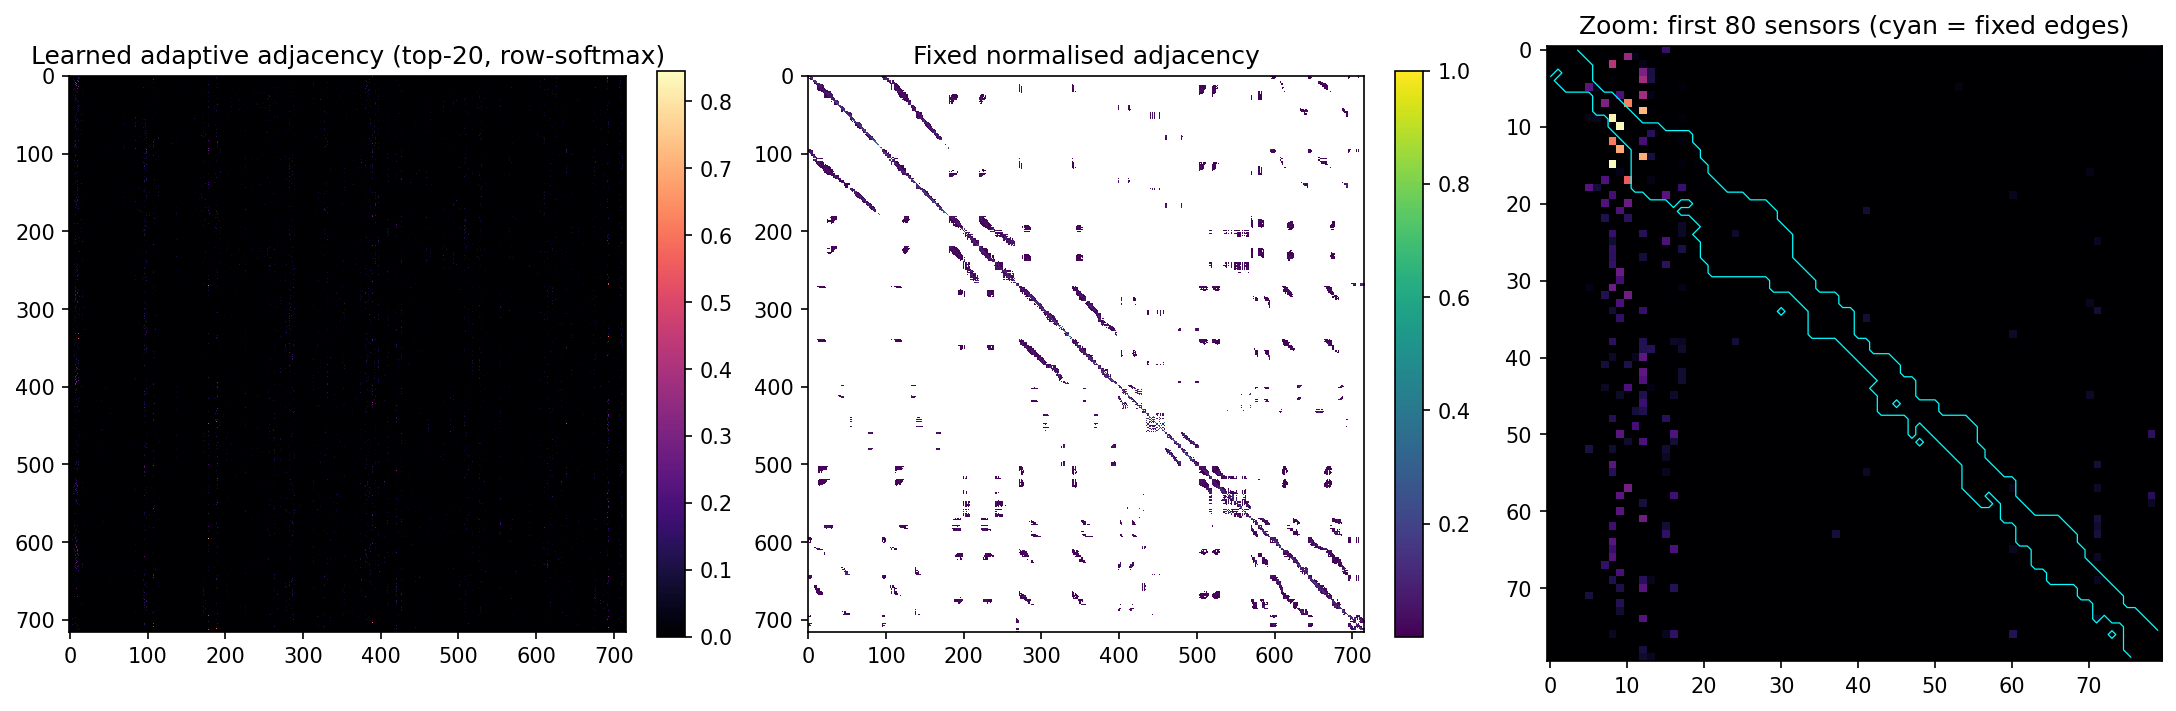

| Adjacency | MAE | RMSE | Training time |
|---|---|---|---|
| Fixed | 61.58 | 97.81 | 235 s |
| Adaptive | **53.08** | **84.71** | 295 s |

The learned graph reduces test MAE by 14% compared with the fixed graph.

### (c) Hybrid adjacency
$$A_{hybrid}=\alpha\,\tilde A_{fixed}+(1-\alpha)\,A_{adaptive},\qquad \tilde A_{fixed}=D_{out}^{-1}(A+I).$$
Both terms are row-stochastic, so they are normalised consistently. $\alpha=\sigma(a)$ is learned, starting at 0.5; it **fell to 0.027** during training.

| Adjacency | MAE | RMSE | Training time |
|---|---|---|---|
| Fixed | 61.58 | 97.81 | 235 s |
| Adaptive | **53.08** | **84.71** | 295 s |
| Hybrid | 54.21 | 85.65 | 238 s |

The model gave the road graph almost no weight, so the hybrid behaves like the adaptive model and ends slightly worse than it.

## Question 6 – Experimental analysis

### (a) Forecasting comparison (test set, Apr–Dec 2021)
| Model | Adjacency | MAE | RMSE | Training time |
|---|---|---|---|---|
| Temporal-only | None | 65.64 | 103.93 | 153 s |
| STGNN | Fixed | 61.58 | 97.81 | 235 s |
| STGNN | Adaptive | **53.08** | **84.71** | 295 s |
| STGNN | Hybrid | 54.21 | 85.65 | 238 s |

**Test MAE by horizon:**

| | 15 min | 30 min | 45 min | 60 min |
|---|---|---|---|---|
| Temporal-only | 45.37 | 59.66 | 72.23 | 85.30 |
| Fixed | 43.32 | 56.02 | 67.51 | 79.49 |
| Adaptive | **40.04** | **49.39** | **57.53** | **65.37** |
| Hybrid | 40.44 | 50.16 | 59.37 | 66.87 |

The figure below shows predicted vs actual flow, 60 minutes ahead, for three sensors over the first test week:

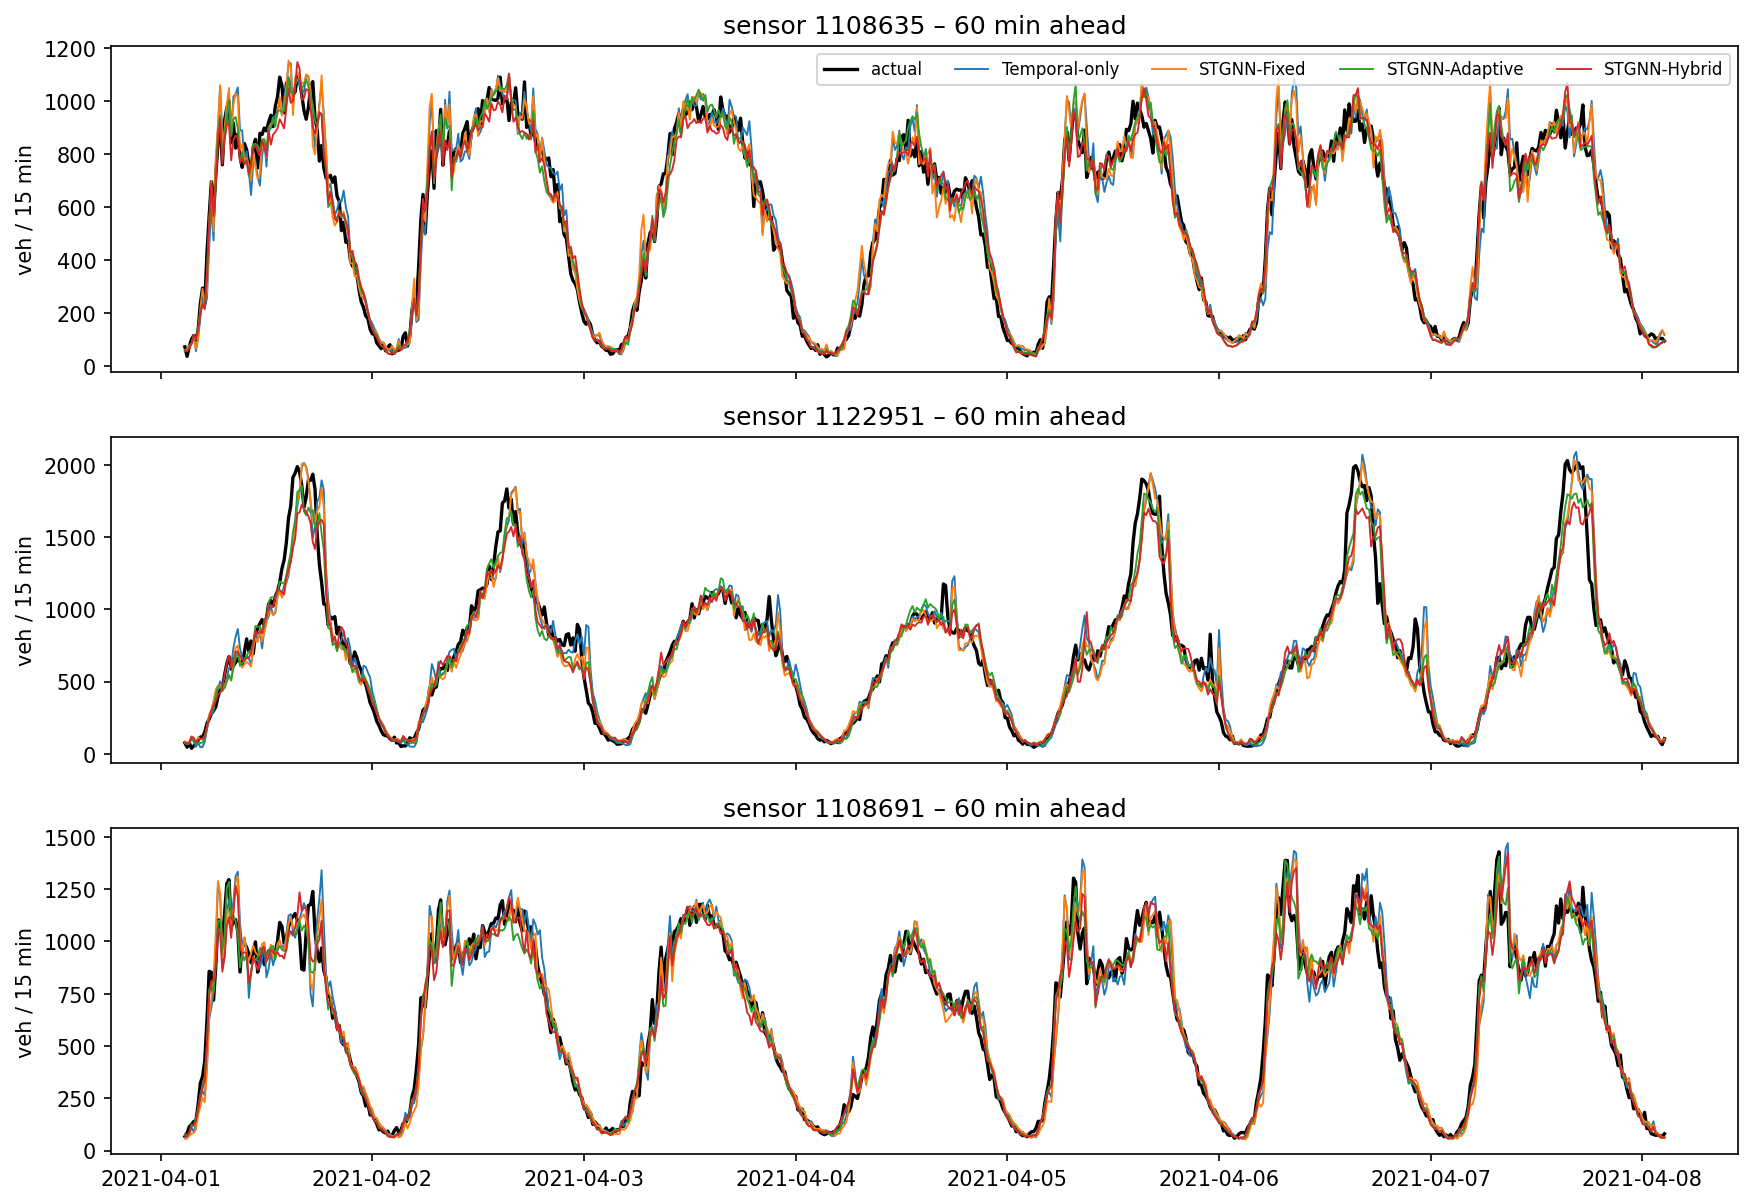

### (b) Graph structure analysis
The comparison uses the 1% strongest off-diagonal learned weights (5,119 edges) of the adaptive model.

| Metric | Learned edges | Road-graph edges | Random pairs |
|---|---|---|---|
| % present in road graph | 4.1% | – | 4.1% (graph density) |
| Median distance (km) | 21.9 | 2.4 | 23.1 |
| Mean training-period correlation | 0.871 | 0.837 | 0.826 |
| % within 2 road hops | 11.5% | – | – |
| % more than 5 hops or unreachable | 61.8% | – | – |

Spearman correlation of learned weight with proximity: 0.03. With training-period correlation: 0.21.

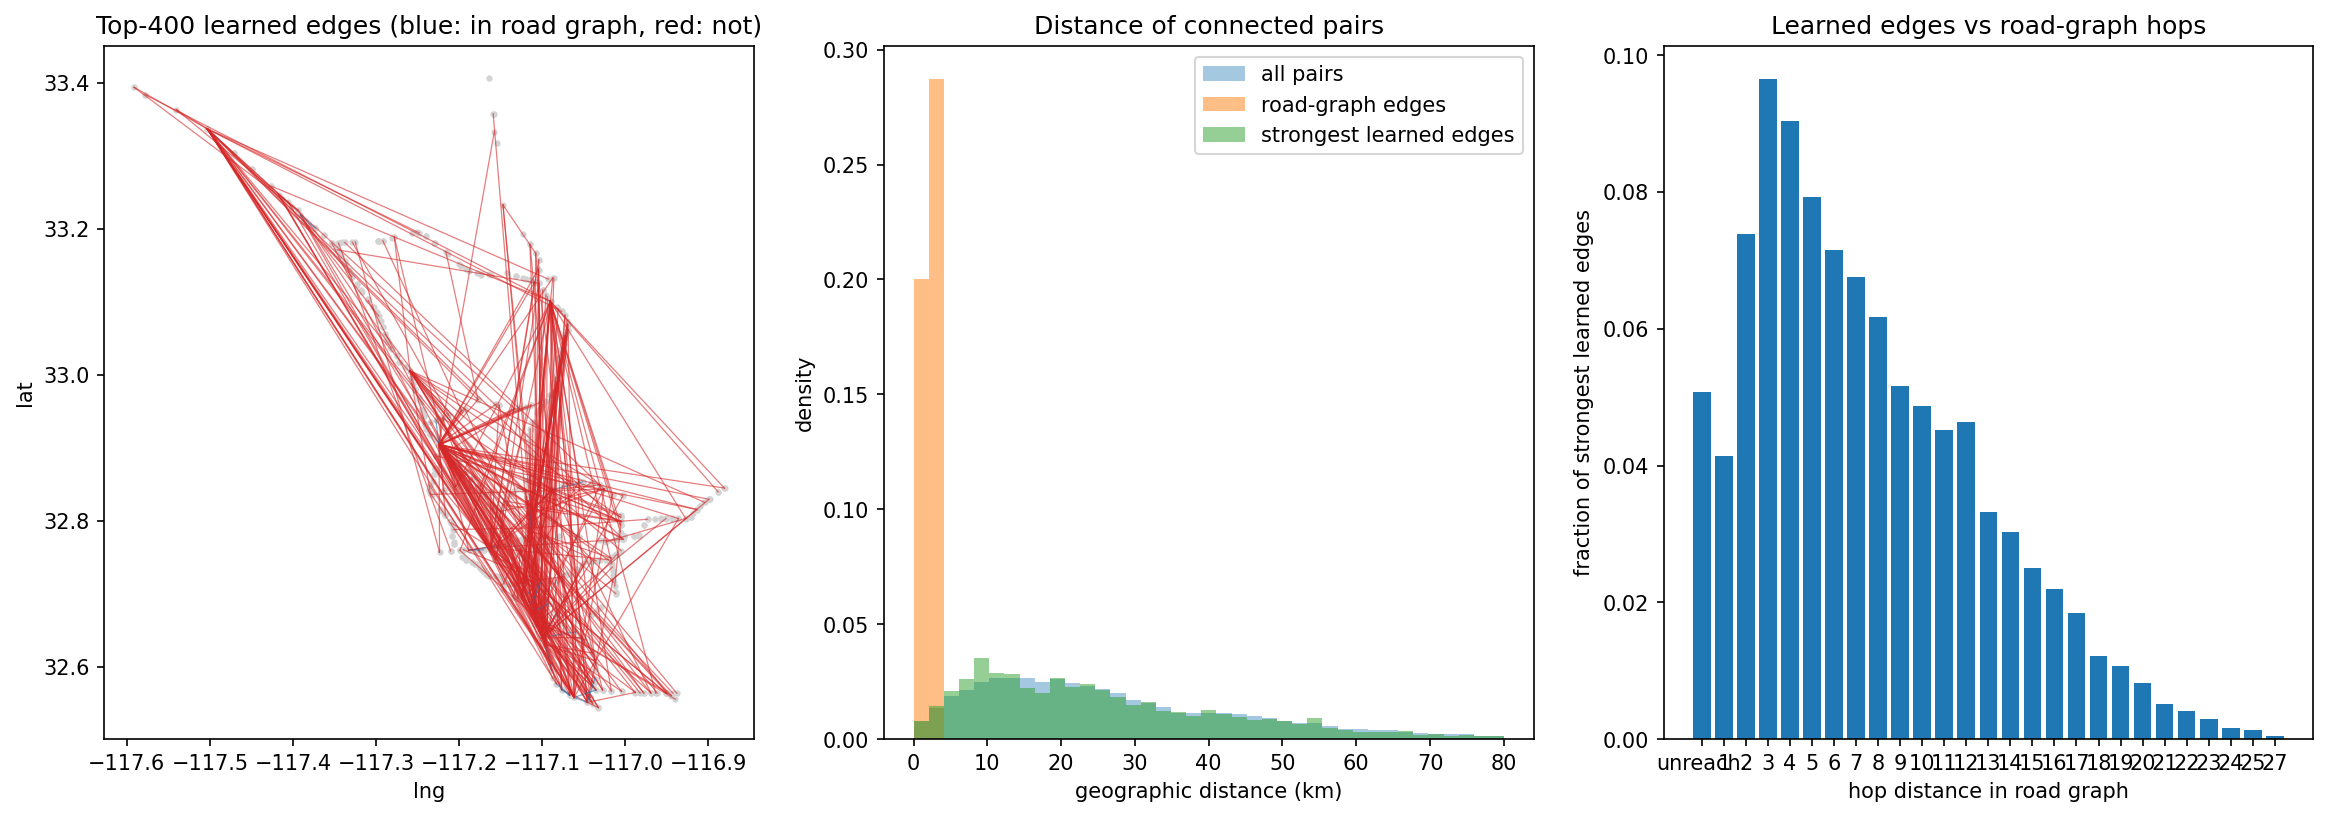

1. **Are the strongest learned connections in the road graph?** No. 4.1% of them are, which is exactly the chance rate.
2. **Are they between geographically nearby sensors?** No. Their median distance (21.9 km) is close to that of random pairs (23.1 km), not road edges (2.4 km), and learned weight is essentially uncorrelated with proximity ($\rho_s=0.03$).
3. **Does the learned graph capture dependencies absent from the physical graph?** Yes. 62% of the strongest learned edges join sensors more than 5 road hops apart, and these pairs have higher traffic correlation (0.871) than road neighbours (0.837). The heatmap's vertical stripes show many sensors attending to the same few "hub" sensors, which act as region-wide summaries of traffic.
4. **Why learned can be better or worse:** it is optimised for the forecasting loss and can link correlated but distant sensors, which the road graph cannot represent. It can be worse because it is learned from one year of data (risk of overfitting), adds $2\times716\times10$ parameters, has no physical meaning, and may need more epochs (the adaptive model's best epoch was 29 of 30).

### (c) Critical discussion
- **Lower error does not mean the graph is the real road network.** The learned graph matches the road graph only at chance level, yet gives the lowest error. It encodes whatever correlations help prediction, such as shared daily cycles and hub sensors, not physical connectivity.
- **Why a hybrid can win:** the road graph gives a reliable local prior, and the learned part adds long-range links. That helps most when data is limited or the learned graph is noisy. Here the learned graph alone was strong enough that $\alpha\to0.03$ and the hybrid matched, but did not beat, the adaptive model.
- **Limits of a static graph:** dependencies change with time of day, weekday vs weekend, incidents and roadworks. For example, upstream influence is strong in rush-hour congestion and weak in free flow. A single fixed or learned matrix averages over these regimes. Time-varying or input-dependent graphs (e.g. attention) can model them.

## Question 7 – Reproducibility

**To reproduce:**
1. Open `24030023_PA3.ipynb` on Kaggle.
2. Attach the dataset `liuxu77/largest` and select a GPU accelerator.
3. Choose *Run All* (about 20 minutes). Outputs are written to `/kaggle/working/outputs`.

**Training configuration**

| Setting | Value |
|---|---|
| Hidden dimension $d$ | 32 |
| Node-embedding dimension $d_e$ | 10 |
| Top-$k$ | 20 |
| Graph layers | 1, with residual skip |
| Optimiser | Adam, lr $10^{-3}$, weight decay $10^{-4}$ (none on $E_1$, $E_2$, $\alpha$) |
| Batch size | 64 |
| Max epochs | 30, early stopping on validation MAE (patience 5) |
| Gradient clipping | 5.0 |
| Loss | Masked MAE |
| Random seed | 42 |

**Epochs and parameters**

| Model | Epochs run | Best epoch | Parameters | Training time |
|---|---|---|---|---|
| Temporal-only | 19 | 14 | 12,644 | 153 s |
| STGNN-Fixed | 27 | 22 | 13,668 | 235 s |
| STGNN-Adaptive | 30 | 29 | 27,988 | 295 s |
| STGNN-Hybrid | 24 | 19 | 27,989 | 238 s |

**Hardware:** Kaggle, NVIDIA Tesla T4 (15.6 GB), 4 CPU cores, 33.7 GB RAM, Python 3.13.16, PyTorch 2.11.0+cu130.